# 02 — Partición y baseline

**Proyecto:** Detección de fraude en transacciones bancarias (Tema 12) — IA 2026-2, UBB

**Objetivo del notebook:** dejar lista la partición train/val/test y medir dos modelos de referencia (baseline)
que los modelos del Avance 2 deben superar en **AUPRC**:
1. `DummyClassifier` «nunca fraude»: muestra que la accuracy engaña.
2. Regresión logística **sin** manejo del desbalance: referencia lineal e interpretable.

**Regla importante:** aquí todo se evalúa **solo en validación**. El conjunto de prueba se separa, pero
no se usa hasta el final del proyecto, una sola vez, para reportar.

> ⚠️ Ejercicio académico: los resultados no constituyen una decisión sobre clientes reales.

## 0. Preparación del entorno

**Qué hacemos:** importamos las librerías y nuestros módulos: `config` (semilla y rutas), `datos` (carga
sin duplicados y partición), `modelos` (definición de los pipelines) y `evaluacion` (métricas y gráficos).

**Por qué:** la carga, la partición y las métricas viven en `src/`, no en el notebook. Así el baseline,
los modelos del Avance 2 y la interfaz usan exactamente los mismos datos y las mismas métricas.

In [1]:
import sys
import time
from pathlib import Path

# Buscar la raíz del proyecto (la carpeta que contiene src/) para poder importar nuestros módulos
RAIZ = Path.cwd()
while not (RAIZ / "src").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.dummy import DummyClassifier

from src.config import RANDOM_STATE, DIR_CAPTURAS
from src.datos import cargar_datos, particionar, tabla_particion
from src.evaluacion import evaluar, graficar_curva_pr, graficar_matriz_confusion
from src.modelos import crear_logistica_sin_balanceo

DIR_DOCS = RAIZ / "docs"
DIR_CAPTURAS.mkdir(parents=True, exist_ok=True)

print("scikit-learn", sklearn.__version__, "| semilla:", RANDOM_STATE)

scikit-learn 1.9.1 | semilla: 42


## 1. Carga y partición estratificada 70/15/15

**Qué hacemos:** cargamos los datos **sin duplicados** (decisión del notebook 01) y los dividimos en
entrenamiento (70 %), validación (15 %) y prueba (15 %) con `particionar()` de `src/datos.py`.

**Por qué en dos pasos:** `train_test_split` solo divide en dos partes. Por eso se encadenan dos llamadas:

| Paso | Entrada | `test_size` | Resultado |
|---|---|---|---|
| 1 | todo el dataset (100 %) | 0,30 | train = 70 % · temporal = 30 % |
| 2 | temporal (30 %) | 0,50 | val = 15 % · test = 15 % |

En el paso 2, `test_size` es 0,50 y no 0,15, porque se aplica sobre el 30 % que quedó, no sobre el total:
0,15 / 0,30 = 0,50.

**Por qué estratificar (`stratify=y`) en ambos pasos:** con solo 473 fraudes, una partición al azar
podría dejar validación o prueba con bastantes menos fraudes que la proporción real. Al estratificar,
los tres conjuntos conservan aproximadamente la misma proporción (≈ 0,167 %).

**Para qué sirve cada conjunto:**
- **train:** ajustar los modelos (y el escalador).
- **val:** comparar modelos y elegir hiperparámetros y umbral.
- **test:** reporte final, una sola vez. Si lo usáramos para decidir, la métrica final sería optimista.

In [2]:
df = cargar_datos()  # elimina duplicados por defecto
X_train, X_val, X_test, y_train, y_val, y_test = particionar(df)

print("Variables de entrada:", X_train.shape[1], "->", list(X_train.columns[:3]), "...", list(X_train.columns[-2:]))
tabla_particion(y_train, y_val, y_test)

Variables de entrada: 30 -> ['Time', 'V1', 'V2'] ... ['V28', 'Amount']


,conjunto,filas,% del total,fraudes,% fraude
0,train,198608,70.0,331,0.1667
1,val,42559,15.0,71,0.1668
2,test,42559,15.0,71,0.1668


**Verificación:** la columna `% fraude` debe ser casi igual en los tres conjuntos. Si no lo fuera, la
estratificación habría fallado. Las filas deben sumar 283.726 y los fraudes 473.

**Preguntas que nos podrían hacer:**

> **¿Por qué el segundo `train_test_split` usa 0,5 y no 0,15?**
> Porque se aplica sobre el 30 % que sobró del primer paso, no sobre el total. La mitad de ese 30 % es
> el 15 % del dataset. Así queda 70 / 15 / 15.

> **¿Para qué sirve el conjunto de validación si ya tienen el de prueba?**
> Para tomar decisiones: qué modelo, qué hiperparámetros y qué umbral usar. Si esas decisiones se tomaran
> mirando el conjunto de prueba, terminaríamos ajustando el modelo a ese conjunto y la métrica final no
> reflejaría su desempeño con datos nuevos. Por eso la prueba se usa una sola vez, al final.

## 2. Métricas de evaluación (`src/evaluacion.py`)

**Qué hacemos:** revisamos las funciones que usarán todos los modelos.
- `evaluar(y_true, puntaje, umbral)` devuelve AUPRC, precisión, recall, F1, accuracy y la matriz de confusión.
- `graficar_curva_pr(...)` dibuja la curva Precisión-Recall con el clasificador aleatorio como referencia.
- `graficar_matriz_confusion(...)` dibuja la matriz de confusión.

**Dos tipos de métrica:**
- **AUPRC** usa el **puntaje de riesgo** continuo y resume el desempeño para **todos** los umbrales posibles.
  No depende del umbral, por eso es la métrica principal para comparar modelos.
- **Precisión, recall, F1, accuracy y la matriz** usan la **decisión** (alertar si `puntaje ≥ umbral`).
  Cambian al mover el umbral, que es justo lo que hará la interfaz.

**Definiciones** (fraude = clase positiva):
- Precisión = TP / (TP + FP): de las alertas, ¿qué fracción eran fraude?
- Recall = TP / (TP + FN): de los fraudes reales, ¿qué fracción detectamos?
- F1 = media armónica de precisión y recall.

**¿Por qué la AUPRC de un clasificador aleatorio es igual a la proporción de fraudes?**
Un clasificador aleatorio asigna puntajes que no tienen relación con la clase real. Entonces, con cualquier
umbral, el grupo de transacciones que alerta es una muestra al azar del total y tiene la misma proporción de
fraudes que el dataset (≈ 0,167 %). Su precisión es ≈ 0,00167 en todos los niveles de recall: la curva PR
es una línea horizontal a esa altura y el área bajo ella es ≈ 0,00167.
Por eso, en este problema, una AUPRC de 0,5 es muy buena, aunque en la curva ROC un 0,5 sea el azar.

In [3]:
# Ejemplo pequeño, calculable a mano, para comprobar que evaluar() hace lo esperado
y_ejemplo       = np.array([0, 0, 0, 0, 1, 1])
puntaje_ejemplo = np.array([0.1, 0.2, 0.7, 0.3, 0.8, 0.4])
# Umbral 0.5 -> alertas en posiciones 2 y 4 -> TP=1 (pos. 4), FP=1 (pos. 2), FN=1 (pos. 5), TN=3
r = evaluar(y_ejemplo, puntaje_ejemplo, umbral=0.5)
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in r.items() if k != "matriz"})
print("Esperado: precision = 1/2 = 0.5, recall = 1/2 = 0.5, accuracy = 4/6 = 0.667")

{'AUPRC': 0.833, 'precision': 0.5, 'recall': 0.5, 'F1': 0.5, 'accuracy': 0.667, 'TP': 1, 'FP': 1, 'FN': 1, 'TN': 3}
Esperado: precision = 1/2 = 0.5, recall = 1/2 = 0.5, accuracy = 4/6 = 0.667


In [4]:
# Comprobación empírica: puntajes al azar -> AUPRC ≈ proporción de fraudes en validación
rng = np.random.default_rng(RANDOM_STATE)
puntaje_azar = rng.random(len(y_val))
print(f"Proporción de fraudes en val: {y_val.mean():.5f}")
print(f"AUPRC de puntajes aleatorios: {evaluar(y_val, puntaje_azar)['AUPRC']:.5f}")

Proporción de fraudes en val: 0.00167
AUPRC de puntajes aleatorios: 0.00163


**Preguntas que nos podrían hacer:**

> **¿Por qué usan AUPRC y no el AUC de la curva ROC?**
> La curva ROC usa la tasa de falsos positivos, FP / (FP + TN). Como hay cientos de miles de legítimas
> (TN enorme), incluso miles de falsas alarmas producen una tasa pequeña y el AUC-ROC se ve muy alto.
> La curva PR usa la precisión, TP / (TP + FP), que sí se ve afectada por esas falsas alarmas. Por eso
> refleja mejor el desempeño en la clase escasa. Además, su referencia aleatoria es la proporción de fraudes
> (0,167 %) y no 0,5.

> **¿La AUPRC depende del umbral?**
> No. Resume todos los umbrales a la vez a partir del puntaje. La precisión y el recall que mostramos en la
> tabla sí dependen del umbral (aquí, 0,5).

## 3. Baseline 1: `DummyClassifier(strategy="most_frequent")`

**Qué hacemos:** entrenamos un "modelo" que siempre predice la clase más frecuente (legítima), sin mirar
las variables.

**Por qué:** es el piso mínimo. Muestra con números que la accuracy engaña: acierta ≈ 99,8 % sin
detectar ningún fraude. Cualquier modelo que propongamos debe superarlo en lo que importa (recall y AUPRC),
no en accuracy.

Como puntaje de riesgo usamos `predict_proba(X)[:, 1]`, la probabilidad de fraude. En este modelo es 0
para todas las transacciones, así que su AUPRC queda igual a la proporción de fraudes, como un modelo
aleatorio.

In [5]:
dummy = DummyClassifier(strategy="most_frequent")

inicio = time.perf_counter()
dummy.fit(X_train, y_train)
tiempo_dummy = time.perf_counter() - inicio

puntaje_dummy = dummy.predict_proba(X_val)[:, 1]  # columna 1 = probabilidad de fraude
res_dummy = evaluar(y_val, puntaje_dummy, umbral=0.5)

print("Puntajes distintos que entrega:", np.unique(puntaje_dummy))
print(f"Accuracy:  {res_dummy['accuracy']:.4f}")
print(f"Recall:    {res_dummy['recall']:.4f}  (fraudes detectados: {res_dummy['TP']} de {int(y_val.sum())})")
print(f"Precisión: {res_dummy['precision']:.4f}  (nunca alerta)")
print(f"AUPRC:     {res_dummy['AUPRC']:.5f}  (= proporción de fraudes en val: {y_val.mean():.5f})")

Puntajes distintos que entrega: [0.]
Accuracy:  0.9983
Recall:    0.0000  (fraudes detectados: 0 de 71)
Precisión: 0.0000  (nunca alerta)
AUPRC:     0.00167  (= proporción de fraudes en val: 0.00167)


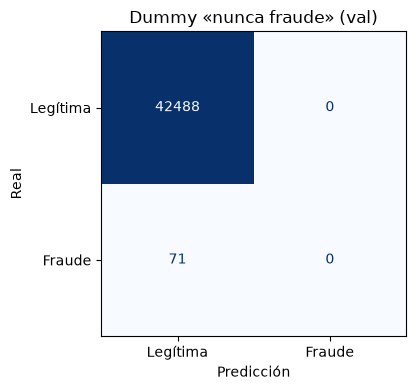

In [6]:
graficar_matriz_confusion(res_dummy["matriz"], titulo="Dummy «nunca fraude» (val)",
                          ruta=DIR_CAPTURAS / "02_matriz_dummy_val.png")
plt.show()

**Preguntas que nos podrían hacer:**

> **¿Para qué incluyen un modelo que no detecta nada?**
> Como referencia mínima y para mostrar que la accuracy engaña. Su ≈ 99,8 % de accuracy, con recall 0,
> deja claro que en este problema hay que mirar recall, precisión y AUPRC.

> **¿Por qué la AUPRC del Dummy es igual a la proporción de fraudes?**
> Porque da el mismo puntaje (0) a todas las transacciones. No ordena nada, así que la única forma de
> detectar fraudes es alertar a todas, y entonces la precisión es la proporción de fraudes. Es el mismo valor
> que obtiene un clasificador aleatorio.

## 4. Baseline 2: regresión logística sin manejo del desbalance

**Qué hacemos:** entrenamos `Pipeline([StandardScaler, LogisticRegression])` **sin** `class_weight` y
**sin** SMOTE. El pipeline **no se define aquí**: se crea con `crear_logistica_sin_balanceo()` de
`src/modelos.py`, la misma función que usa `src/entrenar_baseline.py` para guardar el modelo de la interfaz.
Así hay una sola definición y el notebook y la app no pueden quedar con hiperparámetros distintos.

**Qué es la regresión logística:** calcula una combinación lineal de las variables,
z = w₀ + w₁·x₁ + … + w₃₀·x₃₀, y la pasa por la función sigmoide, σ(z) = 1 / (1 + e⁻ᶻ), que la convierte
en una probabilidad entre 0 y 1. Esa probabilidad es nuestro **puntaje de riesgo**. Los pesos wᵢ se
aprenden minimizando la pérdida logarítmica (log-loss) en entrenamiento.

**Por qué sin manejo del desbalance:** es la referencia contra la que mediremos si `class_weight` y SMOTE
(Avance 2) realmente ayudan. Sin esa corrección, el modelo optimiza el error promedio, que está dominado
por las legítimas.

**Por qué el `StandardScaler` va dentro del pipeline:**
1. Transforma cada variable a media 0 y desviación 1. `Amount` (hasta miles) y `Time` (hasta 172.792 s)
   están en escalas muy distintas a V1–V28. Sin escalar, la regularización castiga los pesos de forma
   desigual entre variables y el optimizador converge peor.
2. Al estar dentro del pipeline, `fit` ajusta el escalador **solo con train**, y `predict_proba(X_val)`
   reutiliza esa media y desviación sin recalcularlas. Si escaláramos antes de partir, la información de
   val/test se filtraría al entrenamiento (fuga de información). Lo mismo pasará dentro de la validación
   cruzada del Avance 2.

**Hiperparámetros:**

| Parámetro | Valor | Qué hace |
|---|---|---|
| `solver` | `"lbfgs"` | Algoritmo de optimización (cuasi-Newton) que encuentra los pesos. Es el valor por defecto y funciona bien con muchas filas y pocas variables. |
| `C` | `1.0` | Inverso de la fuerza de regularización L2 (que penaliza pesos grandes para evitar sobreajuste). C chico = más regularización. Se deja el valor por defecto. Compararlo con otros valores es tarea del Avance 2. |
| `max_iter` | `1000` | Máximo de iteraciones del optimizador. El valor por defecto (100) a veces no alcanza para converger y sklearn lanza una `ConvergenceWarning`. Con 1000 hay margen. |

No se fija `random_state` porque `lbfgs` es determinista: da el mismo resultado en cada ejecución.

**Umbral:** por ahora 0,5, que es el que usa `predict()`. No es necesariamente el mejor para fraude.
Elegirlo con validación es parte del Avance 2 y de la interfaz.

In [7]:
# Definición única en src/modelos.py: Pipeline([("escalado", StandardScaler()),
#                                              ("modelo", LogisticRegression(solver="lbfgs", C=1.0, max_iter=1000))])
logistica = crear_logistica_sin_balanceo()
print(logistica)  # muestra los pasos y los hiperparámetros distintos del valor por defecto

inicio = time.perf_counter()
logistica.fit(X_train, y_train)  # el escalador se ajusta SOLO con train
tiempo_logistica = time.perf_counter() - inicio

puntaje_logistica = logistica.predict_proba(X_val)[:, 1]  # el escalador aplica la media/desv. de train
res_logistica = evaluar(y_val, puntaje_logistica, umbral=0.5)

print(f"Tiempo de entrenamiento: {tiempo_logistica:.2f} s")
print(f"Iteraciones usadas por lbfgs: {logistica.named_steps['modelo'].n_iter_[0]} (máximo 1000)")
print(f"AUPRC:     {res_logistica['AUPRC']:.4f}")
print(f"Precisión: {res_logistica['precision']:.4f}")
print(f"Recall:    {res_logistica['recall']:.4f}  (fraudes detectados: {res_logistica['TP']} de {int(y_val.sum())})")
print(f"Accuracy:  {res_logistica['accuracy']:.4f}")

Pipeline(steps=[('escalado', StandardScaler()),
                ('modelo', LogisticRegression(max_iter=1000))])
Tiempo de entrenamiento: 0.40 s
Iteraciones usadas por lbfgs: 16 (máximo 1000)
AUPRC:     0.6877
Precisión: 0.8333
Recall:    0.4930  (fraudes detectados: 35 de 71)
Accuracy:  0.9990


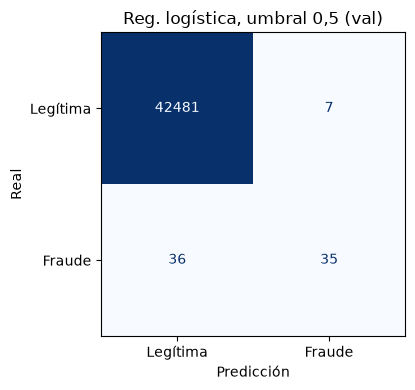

In [8]:
graficar_matriz_confusion(res_logistica["matriz"], titulo="Reg. logística, umbral 0,5 (val)",
                          ruta=DIR_CAPTURAS / "02_matriz_logistica_val.png")
plt.show()

**Preguntas que nos podrían hacer:**

> **¿Por qué el escalador está dentro del pipeline y no se aplica antes de partir los datos?**
> Para que su media y desviación se calculen solo con entrenamiento. Si se ajustara con todo el dataset,
> información de validación y prueba se filtraría al modelo. Con el pipeline, `fit` ajusta el escalador
> solo con train y `predict_proba` lo reutiliza sobre val y test sin recalcularlo.

> **¿Qué significa C = 1,0 y qué pasaría si lo bajan?**
> C es el inverso de la fuerza de regularización L2. Con un C más chico se penalizan más los pesos grandes:
> el modelo queda más simple y con menos riesgo de sobreajuste, pero puede perder señal. Probar varios
> valores de C en validación es una de las configuraciones que vamos a comparar.

## 5. Tabla comparativa y curva Precisión-Recall (validación)

**Qué hacemos:** juntamos las métricas de ambos baselines en una tabla, la guardamos en
`docs/resultados_baseline_val.csv` y graficamos sus curvas PR junto a la referencia aleatoria.

**Por qué:** la tabla es la evidencia del Avance 1 y la base contra la que se compararán los modelos del
Avance 2. Registramos el tiempo de entrenamiento porque también importa en la comparación (Random Forest y
SMOTE van a tardar más). El CSV permite agregar filas después sin rehacer este notebook.

In [9]:
filas = []
for nombre, res, tiempo in [
    ("Dummy «nunca fraude»", res_dummy, tiempo_dummy),
    ("Regresión logística (sin balanceo)", res_logistica, tiempo_logistica),
]:
    fila = {"modelo": nombre, "conjunto": "val", "umbral": 0.5}
    fila.update({k: v for k, v in res.items() if k != "matriz"})
    fila["tiempo_entrenamiento_s"] = tiempo
    filas.append(fila)

tabla = pd.DataFrame(filas)
tabla.to_csv(DIR_DOCS / "resultados_baseline_val.csv", index=False)
print("Guardado en", DIR_DOCS / "resultados_baseline_val.csv")

tabla.round(4)

Guardado en C:\Users\canto\.gemini\antigravity\scratch\ProyectoIA-fraude\docs\resultados_baseline_val.csv


,modelo,conjunto,umbral,AUPRC,precision,recall,F1,accuracy,TP,FP,FN,TN,tiempo_entrenamiento_s
0,Dummy «nunca fraude»,val,0.5,0.0017,0.0000,0.000,0.0000,0.9983,0,0,71,42488,0.0122
1,Regresión logística (sin balanceo),val,0.5,0.6877,0.8333,0.493,0.6195,0.9990,35,7,36,42481,0.3962


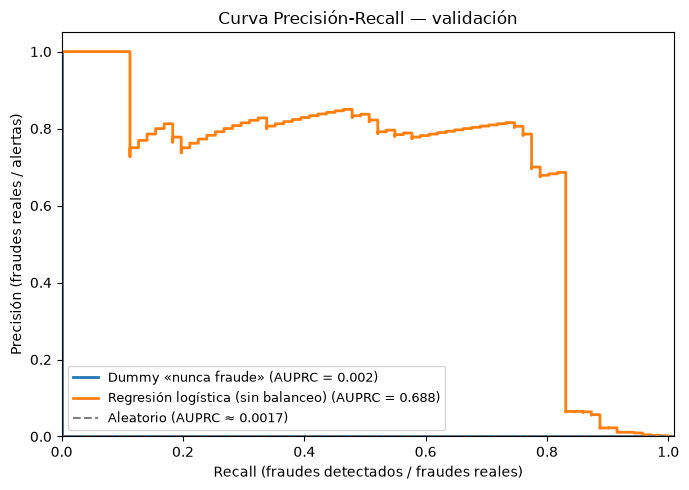

In [10]:
graficar_curva_pr(
    y_val,
    {"Dummy «nunca fraude»": puntaje_dummy, "Regresión logística (sin balanceo)": puntaje_logistica},
    titulo="Curva Precisión-Recall — validación",
    ruta=DIR_CAPTURAS / "02_curva_pr_val.png",
)
plt.show()

**Cómo leer la curva:** cada punto corresponde a un umbral. Moverse a la derecha (bajar el umbral) detecta
más fraudes (más recall), pero normalmente con más falsas alarmas (menos precisión). La línea punteada
es el azar. La curva del Dummy queda pegada a ella (en el suelo del gráfico): no ordena nada, igual que el azar. Mientras más área deje la curva por encima de ella, mejor ordena el modelo las transacciones
por riesgo.

**Preguntas que nos podrían hacer:**

> **¿Por qué evalúan en validación y no en prueba?**
> Porque todavía estamos comparando y tomando decisiones. El conjunto de prueba queda reservado para el
> reporte final, una sola vez, para que su métrica sea una estimación honesta del desempeño con datos nuevos.

> **¿Qué representa cada punto de la curva PR?**
> Un umbral distinto. Para ese umbral se cuentan las alertas y se calculan la precisión (qué fracción de las
> alertas era fraude) y el recall (qué fracción de los fraudes se detectó). La interfaz permitirá moverse
> por esta curva con el slider del umbral.

## 6. Interpretación y expectativas para el Avance 2 (TODO equipo)

1. El Dummy «nunca fraude» obtiene 99,83 % de accuracy sin detectar ningún fraude (recall 0, AUPRC 0,0017). Esto confirma que la accuracy no sirve como métrica con clases tan desbalanceadas: un modelo que no hace nada parece casi perfecto.

2. La regresión logística sin balanceo multiplica la AUPRC del azar por ~400 (0,688 vs 0,0017), lo que muestra que las variables sí tienen poder predictivo. Sin embargo, con umbral 0,5 se escapa la mitad de los fraudes (recall 0,493: solo 35 de 71 detectados). Esto ocurre porque el modelo se entrenó sin compensar el desbalance y la mayoría de sus puntajes son bajos — muchos fraudes quedan bajo 0,5.

3. Bajando el umbral a 0,1 el recall sube a 0,718 (51 fraudes detectados) con solo 5 falsas alarmas más que con umbral 0,5. Esto muestra que el umbral por defecto no es el más adecuado para este problema.

4. Qué esperamos del Avance 2:

- class_weight="balanced" debería subir el recall sin crear datos nuevos, al penalizar más los errores en fraude durante el entrenamiento.
- SMOTE crearía fraudes sintéticos en el entrenamiento para equilibrar las clases, pero aplicado solo dentro del pipeline para no contaminar validación ni prueba.
- Random Forest debería capturar relaciones no lineales que la regresión logística no puede, mejorando la AUPRC.
- La elección formal del umbral óptimo se hará en el Avance 2 evaluando en prueba una sola vez.